# Genetic Algorithm

**Data dasar (Bagian 2.1 modul):** kapasitas tas 8 kg, setiap barang boleh dipilih satu kali.

| Barang | Bobot (kg) | Nilai |
|---|---|---|
| A | 2 | 6 |
| B | 3 | 5 |
| C | 4 | 8 |
| D | 5 | 9 |

Kromosom ditulis sebagai 4 bit berurutan A–B–C–D (1 = dipilih).

## Setup

In [1]:
import random
import itertools
import statistics
import matplotlib.pyplot as plt

NAMA = ("A", "B", "C", "D")
BOBOT = (2, 3, 4, 5)
NILAI = (6, 5, 8, 9)
KAPASITAS = 8

## Soal 1: Fitness dan Enumerasi

a. Hitung bobot, nilai, dan fitness (penalti: fitness 0 jika bobot > 8) untuk kromosom `1001`, `0110`, `1100`, `1111`, `1010`, `0101`.

b. Enumerasikan seluruh $2^4 = 16$ kromosom. Berapa fitness maksimum dan kromosom mana yang mencapainya?

### Penyelesaian

$$F(x)=\begin{cases}\sum_i v_i x_i, & \sum_i w_i x_i \le 8\\ 0, & \text{lainnya}\end{cases}$$

In [2]:
def ukur(kromosom, bobot=BOBOT, nilai=NILAI):
    berat = sum(b * g for b, g in zip(bobot, kromosom))
    total = sum(v * g for v, g in zip(nilai, kromosom))
    return berat, total

def fitness(kromosom, bobot=BOBOT, nilai=NILAI, kapasitas=KAPASITAS):
    berat, total = ukur(kromosom, bobot, nilai)
    return total if berat <= kapasitas else 0

def bits(s):
    return [int(c) for c in s]

print(f"{'Kromosom':<9}{'Barang':<12}{'Bobot':>6}{'Nilai':>6}{'Fitness':>8}")
for s in ["1001", "0110", "1100", "1111", "1010", "0101"]:
    k = bits(s)
    b, v = ukur(k)
    barang = ", ".join(n for n, g in zip(NAMA, k) if g)
    print(f"{s:<9}{barang:<12}{b:>6}{v:>6}{fitness(k):>8}")

Kromosom Barang       Bobot Nilai Fitness
1001     A, D             7    15      15
0110     B, C             7    13      13
1100     A, B             5    11      11
1111     A, B, C, D      14    28       0
1010     A, C             6    14      14
0101     B, D             8    14      14


In [3]:
semua = [list(k) for k in itertools.product([0, 1], repeat=4)]
for k in semua:
    b, v = ukur(k)
    print("".join(map(str, k)), f"bobot={b:2d} nilai={v:2d} fitness={fitness(k):2d}")

optimum = max(map(fitness, semua))
terbaik = ["".join(map(str, k)) for k in semua if fitness(k) == optimum]
print("\nFitness maksimum:", optimum, "dicapai oleh", terbaik)
assert optimum == 15 and terbaik == ["1001"]

0000 bobot= 0 nilai= 0 fitness= 0
0001 bobot= 5 nilai= 9 fitness= 9
0010 bobot= 4 nilai= 8 fitness= 8
0011 bobot= 9 nilai=17 fitness= 0
0100 bobot= 3 nilai= 5 fitness= 5
0101 bobot= 8 nilai=14 fitness=14
0110 bobot= 7 nilai=13 fitness=13
0111 bobot=12 nilai=22 fitness= 0
1000 bobot= 2 nilai= 6 fitness= 6
1001 bobot= 7 nilai=15 fitness=15
1010 bobot= 6 nilai=14 fitness=14
1011 bobot=11 nilai=23 fitness= 0
1100 bobot= 5 nilai=11 fitness=11
1101 bobot=10 nilai=20 fitness= 0
1110 bobot= 9 nilai=19 fitness= 0
1111 bobot=14 nilai=28 fitness= 0

Fitness maksimum: 15 dicapai oleh ['1001']


**Jawaban:** `1111` bernilai 28 tetapi bobot 14 kg > 8, sehingga fitness 0. Fitness maksimum adalah **15** oleh `1001` (A dan D, 7 kg). Nilai ini menjadi pembanding hasil GA.

## Soal 2: Operator Genetika Secara Manual

a. Lakukan seleksi turnamen (2 peserta) untuk pasangan `1001` vs `0110` dan `0110` vs `1100`.

b. Lakukan crossover satu titik setelah gen B pada induk `1001` dan `0110`. Hitung fitness kedua anak.

c. Lakukan mutasi bit-flip pada gen D kromosom `1000`. Berapa fitness sebelum dan sesudah?

### Penyelesaian

In [4]:
# a. turnamen: pemenang = fitness tertinggi
for p1, p2 in [("1001", "0110"), ("0110", "1100")]:
    menang = max([bits(p1), bits(p2)], key=fitness)
    print(f"{p1} ({fitness(bits(p1))}) vs {p2} ({fitness(bits(p2))}) -> {''.join(map(str, menang))}")

# b. crossover satu titik, titik = 2 (setelah gen B)
i1, i2, titik = bits("1001"), bits("0110"), 2
a1, a2 = i1[:titik] + i2[titik:], i2[:titik] + i1[titik:]
for a in (a1, a2):
    print("Anak", "".join(map(str, a)), "bobot/nilai =", ukur(a), "fitness =", fitness(a))
assert (a1, a2) == (bits("1010"), bits("0101"))

# c. mutasi gen D (indeks 3)
k = bits("1000")
m = k[:]; m[3] = 1 - m[3]
print("Mutasi", "".join(map(str, k)), "->", "".join(map(str, m)), ":", fitness(k), "->", fitness(m))
assert fitness(m) == 15

1001 (15) vs 0110 (13) -> 1001
0110 (13) vs 1100 (11) -> 0110
Anak 1010 bobot/nilai = (6, 14) fitness = 14
Anak 0101 bobot/nilai = (8, 14) fitness = 14
Mutasi 1000 -> 1001 : 6 -> 15


**Jawaban:** pemenang turnamen `1001` dan `0110`. Anak crossover `1010` (A, C; 6 kg; 14) dan `0101` (B, D; 8 kg; 14): keduanya tidak lebih baik dari induk 1 (15). Mutasi `1000`→`1001` menaikkan fitness 6→15.

## Soal 3: Implementasi GA

Implementasikan GA sesuai pseudocode modul (turnamen 2 peserta, crossover satu titik, mutasi bit-flip per gen, elitisme) dengan parameter $N=20$, $G=30$, $p_c=0{,}8$, $p_m=0{,}1$, $E=2$, `seed=4`. Tampilkan solusi terbaik dan grafik fitness terbaik per generasi.

### Penyelesaian

Fungsi dibuat umum (menerima `fit` dan panjang kromosom) agar bisa dipakai lagi di Soal 5.

In [5]:
def turnamen(populasi, rng, fit, ukuran=2):
    return max(rng.sample(populasi, ukuran), key=fit)[:]

def crossover(induk1, induk2, rng, peluang):
    if rng.random() >= peluang:
        return induk1[:], induk2[:]
    titik = rng.randrange(1, len(induk1))
    return induk1[:titik] + induk2[titik:], induk2[:titik] + induk1[titik:]

def mutasi(kromosom, rng, peluang):
    for i in range(len(kromosom)):
        if rng.random() < peluang:
            kromosom[i] = 1 - kromosom[i]
    return kromosom

def algoritma_genetika(seed=4, jumlah=20, generasi=30, peluang_crossover=0.8,
                       peluang_mutasi=0.1, jumlah_elit=2, fit=fitness, n_gen=4):
    if not (2 <= jumlah and 0 <= jumlah_elit < jumlah):
        raise ValueError("Ukuran populasi/elit tidak valid")
    if not (0 <= peluang_crossover <= 1 and 0 <= peluang_mutasi <= 1):
        raise ValueError("Peluang harus antara 0 dan 1")
    rng = random.Random(seed)
    populasi = [[rng.randrange(2) for _ in range(n_gen)] for _ in range(jumlah)]
    riwayat = [max(map(fit, populasi))]
    for _ in range(generasi):
        urut = sorted(populasi, key=fit, reverse=True)
        baru = [ind[:] for ind in urut[:jumlah_elit]]
        while len(baru) < jumlah:
            a1, a2 = crossover(turnamen(populasi, rng, fit), turnamen(populasi, rng, fit),
                               rng, peluang_crossover)
            for anak in (a1, a2):
                if len(baru) < jumlah:
                    baru.append(mutasi(anak, rng, peluang_mutasi))
        populasi = baru
        riwayat.append(max(map(fit, populasi)))
    return max(populasi, key=fit), riwayat

Kromosom: 1001
Barang: A, D
Bobot: 7 kg
Nilai: 15
Fitness awal/akhir: 14 / 15


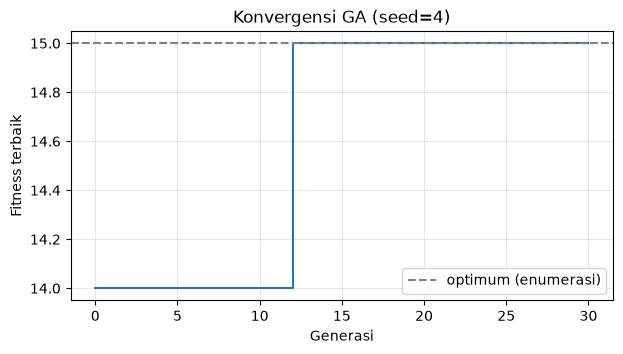

In [6]:
terbaik, riwayat = algoritma_genetika()
berat, nilai = ukur(terbaik)
print("Kromosom:", "".join(map(str, terbaik)))
print("Barang:", ", ".join(n for n, g in zip(NAMA, terbaik) if g) or "(tidak ada)")
print("Bobot:", berat, "kg")
print("Nilai:", nilai)
print("Fitness awal/akhir:", riwayat[0], "/", riwayat[-1])
assert fitness(terbaik) == optimum
# elitisme => fitness terbaik tidak pernah turun
assert all(b >= a for a, b in zip(riwayat, riwayat[1:]))

plt.figure(figsize=(7, 3.5))
plt.step(range(len(riwayat)), riwayat, where="post")
plt.axhline(optimum, ls="--", c="gray", label="optimum (enumerasi)")
plt.xlabel("Generasi"); plt.ylabel("Fitness terbaik"); plt.title("Konvergensi GA (seed=4)")
plt.legend(); plt.grid(alpha=.3); plt.show()

**Jawaban:** GA menemukan `1001` (A, D; 7 kg; nilai 15), sama dengan optimum enumerasi. Berkat elitisme, kurva fitness terbaik tidak pernah turun.

## Soal 4: Evaluasi dengan Banyak Seed dan Pengaruh $p_m$

a. Jalankan GA dengan 30 seed berbeda. Laporkan fitness terbaik, rata-rata, simpangan baku, dan persentase run yang mencapai optimum. Bandingkan dengan **pencarian acak** dengan anggaran evaluasi yang sama ($N \times (G+1) = 620$ kromosom).

b. Ulangi (a) untuk $p_m \in \{0;\ 0{,}01;\ 0{,}1;\ 0{,}3;\ 0{,}5\}$. Apa pengaruhnya?

### Penyelesaian

In [7]:
SEEDS = range(30)

def ringkas(hasil, opt):
    return (max(hasil), statistics.mean(hasil), statistics.pstdev(hasil),
            100 * sum(h == opt for h in hasil) / len(hasil))

def pencarian_acak(seed, anggaran, fit=fitness, n_gen=4):
    rng = random.Random(seed)
    return max(fit([rng.randrange(2) for _ in range(n_gen)]) for _ in range(anggaran))

ga = [algoritma_genetika(seed=s)[1][-1] for s in SEEDS]
acak = [pencarian_acak(s, 20 * 31) for s in SEEDS]
print(f"{'Metode':<16}{'terbaik':>8}{'rata2':>8}{'std':>7}{'%optimum':>10}")
for nama, h in [("GA", ga), ("Pencarian acak", acak)]:
    print(f"{nama:<16}" + "{:>8}{:>8.2f}{:>7.2f}{:>9.0f}%".format(*ringkas(h, optimum)))

Metode           terbaik   rata2    std  %optimum
GA                    15   15.00   0.00      100%
Pencarian acak        15   15.00   0.00      100%


In [8]:
print(f"{'p_m':>5}{'terbaik':>9}{'rata2':>8}{'std':>7}{'%optimum':>10}")
for pm in [0, 0.01, 0.1, 0.3, 0.5]:
    h = [algoritma_genetika(seed=s, peluang_mutasi=pm)[1][-1] for s in SEEDS]
    print(f"{pm:>5}" + "{:>9}{:>8.2f}{:>7.2f}{:>9.0f}%".format(*ringkas(h, optimum)))

  p_m  terbaik   rata2    std  %optimum


    0       15   14.90   0.30       90%


 0.01       15   14.90   0.30       90%


  0.1       15   15.00   0.00      100%
  0.3       15   15.00   0.00      100%


  0.5       15   15.00   0.00      100%


**Jawaban:**
- Pada masalah 4 gen (hanya 16 kemungkinan), pencarian acak dengan 620 evaluasi hampir pasti menemukan optimum, sehingga GA **tidak** unggul di sini. Ini sesuai modul: untuk masalah sekecil ini enumerasi lebih sederhana.
- $p_m = 0$: tidak ada sumber variasi baru selain crossover; jika populasi awal tidak memuat gen yang dibutuhkan, GA dapat terjebak. $p_m$ moderat (≈0,1) menjaga keragaman. $p_m$ besar mendekati pencarian acak; elitisme tetap mencegah fitness terbaik turun.
- Perbedaan GA vs pencarian acak baru terlihat pada ruang pencarian besar: lihat Soal 5.

## Soal 5: Knapsack 30 Barang, Penalti vs Perbaikan (*Repair*)

Buat knapsack acak 30 barang (`seed=0`, bobot 1–20, nilai 1–30, kapasitas = 40% total bobot). Ruang pencarian $2^{30} \approx 10^9$, terlalu besar untuk enumerasi.

a. Hitung optimum eksak dengan *dynamic programming* sebagai pembanding.

b. Bandingkan GA dengan fitness **penalti** (fitness 0 bila melanggar) vs fitness **repair** (buang barang dengan rasio nilai/bobot terendah sampai muat), serta pencarian acak dengan anggaran sama. Gunakan $N=50$, $G=100$, $p_m = 1/30$, 20 seed.

### Penyelesaian

In [9]:
rng0 = random.Random(0)
n = 30
W = [rng0.randint(1, 20) for _ in range(n)]
V = [rng0.randint(1, 30) for _ in range(n)]
CAP = int(0.4 * sum(W))

def knapsack_dp(bobot, nilai, kapasitas):
    dp = [0] * (kapasitas + 1)
    for w, v in zip(bobot, nilai):
        for c in range(kapasitas, w - 1, -1):
            dp[c] = max(dp[c], dp[c - w] + v)
    return dp[kapasitas]

OPT30 = knapsack_dp(W, V, CAP)
assert knapsack_dp(BOBOT, NILAI, KAPASITAS) == 15  # cek DP pada data modul
print("Kapasitas:", CAP, "| Optimum eksak (DP):", OPT30)

Kapasitas: 135 | Optimum eksak (DP): 380


In [10]:
def fit_penalti(k):
    return fitness(k, W, V, CAP)

URUT_RASIO = sorted(range(n), key=lambda i: V[i] / W[i])  # rasio terendah dulu

def fit_repair(k):
    k = k[:]
    berat = sum(w * g for w, g in zip(W, k))
    for i in URUT_RASIO:
        if berat <= CAP:
            break
        if k[i]:
            k[i], berat = 0, berat - W[i]
    return sum(v * g for v, g in zip(V, k))

param = dict(jumlah=50, generasi=100, peluang_mutasi=1 / n, n_gen=n)
SEEDS20 = range(20)
hasil = {
    "GA penalti": [algoritma_genetika(seed=s, fit=fit_penalti, **param)[1] for s in SEEDS20],
    "GA repair":  [algoritma_genetika(seed=s, fit=fit_repair, **param)[1] for s in SEEDS20],
}
acak30 = [pencarian_acak(s, 50 * 101, fit_penalti, n) for s in SEEDS20]

print(f"{'Metode':<16}{'terbaik':>8}{'rata2':>9}{'std':>7}{'%optimum':>10}{'gap rata2':>11}")
for nama, h in [*[(k, [r[-1] for r in v]) for k, v in hasil.items()], ("Pencarian acak", acak30)]:
    t, m, sd, p = ringkas(h, OPT30)
    print(f"{nama:<16}{t:>8}{m:>9.1f}{sd:>7.2f}{p:>9.0f}%{100 * (OPT30 - m) / OPT30:>10.1f}%")

Metode           terbaik    rata2    std  %optimum  gap rata2
GA penalti           380    377.5   2.16       20%       0.7%
GA repair            380    379.2   0.43       25%       0.2%
Pencarian acak       348    326.9  11.28        0%      14.0%


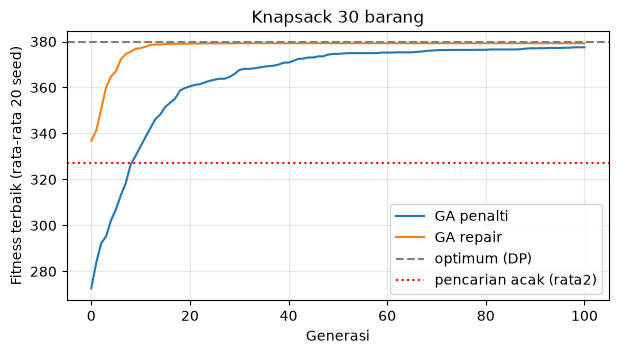

In [11]:
plt.figure(figsize=(7, 3.5))
for nama, runs in hasil.items():
    rata = [statistics.mean(g) for g in zip(*runs)]
    plt.plot(rata, label=nama)
plt.axhline(OPT30, ls="--", c="gray", label="optimum (DP)")
plt.axhline(statistics.mean(acak30), ls=":", c="red", label="pencarian acak (rata2)")
plt.xlabel("Generasi"); plt.ylabel("Fitness terbaik (rata-rata 20 seed)")
plt.title("Knapsack 30 barang"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Jawaban:**
- Pada ruang pencarian besar, kedua varian GA jauh mengungguli pencarian acak dengan anggaran evaluasi sama.
- **Penalti 0** membuang informasi: solusi yang sedikit melebihi kapasitas dinilai sama buruknya dengan solusi yang sangat melanggar, sehingga awal pencarian lambat (banyak individu acak berfitness 0).
- **Repair** selalu memberi skor solusi layak terdekat, sehingga konvergensi lebih cepat dan hasil lebih dekat ke optimum DP.
- GA tetap heuristik: tidak semua seed mencapai optimum, sehingga evaluasi perlu banyak seed dan pembanding eksak/sederhana, seperti disarankan modul Bagian 6.

## Kesimpulan

1. Fitness dengan penalti menolak solusi tak layak (`1111` → 0); optimum data modul adalah `1001` (A, D; 7 kg; nilai 15).
2. Seleksi turnamen, crossover satu titik, dan mutasi bit-flip menghasilkan variasi; anak belum tentu lebih baik, sehingga fitness selalu dihitung ulang.
3. Elitisme menjamin fitness terbaik tidak menurun antar generasi.
4. Pada masalah kecil, enumerasi/pencarian acak sudah cukup; keunggulan GA muncul pada ruang pencarian besar.
5. Penanganan batasan (penalti vs repair) sangat memengaruhi kinerja GA.